# Import modules

In [ ]:
import xarray as xr
import numpy as np
import cftime
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from itertools import cycle
import functools
from matplotlib import animation
from textwrap import wrap

# Functions

In [ ]:
def sizedist(group_name, group_type, bins, wet_radius, numdensity): 
    bin_str = [ str(int(n)) if n > 9 else "0"+str(int(n)) for n in bins]
    
    if group_type == 'standard':        
        reff_tmp = []
        dist_tmp = []
        for bn in bin_str:
            reff_tmp.append(wet_radius[group_name + bn + 'WR']) 
            dist_tmp.append(numdensity[group_name + bn + 'ND'])
        reff = xr.concat(reff_tmp, dim='bin').assign_coords({"bin": bins}).assign_attrs(units=wet_radius[group_name + bn + 'WR'].units, description='Bin radius')
        dist = xr.concat(dist_tmp, dim='bin').assign_coords({"bin": bins})
        
        dr = np.zeros(np.shape(reff))
        dr[0, :] = reff.sel(bin=bins[1]).values - reff.sel(bin=bins[0]).values
        dr[-1, :] = reff.sel(bin=bins[-1]).values - reff.sel( bin=bins[-2]).values
        # dr[0, :] = (reff.sel(bin=bins[1]).values - reff.sel(bin=bins[0]).values) * reff.sel(bin=bins[0]).values/reff.sel(bin=bins[1]).values
        # dr[-1, :] = (reff.sel(bin=bins[-1]).values - reff.sel( bin=bins[-2]).values)  * reff.sel(bin=bins[-2]).values/reff.sel(bin=bins[-1]).values

        for b, bn in enumerate(bins[1:-1]):
            b +=1
            vp = reff.sel(bin=bins[b+1]).values
            vm = reff.sel(bin=bins[b-1]).values
            v0 = reff.sel(bin=bins[b]).values
            dr[b, :] = np.sqrt(vp*v0) - np.sqrt(vm*v0)
        dreff = xr.DataArray(data=dr, name='dr', coords=reff.coords, dims=reff.dims)
        
        dist = dist/dreff*reff
        dist = dist.assign_attrs(long_name='Aerosol size distribution', units= "#/cm3", description='dN/dlogr')

    
    elif group_type == 'fractal':
        dist_tmp = []
        for bn in bin_str:
            dist_tmp.append(numdensity[group_name + bn + 'ND'])
            
        tmp = xr.concat(dist_tmp, dim='bin').assign_coords({"bin": bins})   
        tmp = tmp/ tmp.sum('bin')
        dist = tmp.assign_attrs(long_name="Fraction of agglomerates", units='', description='Fraction')


    return dist


# Definitions

In [ ]:
in_dir = "../../run/carma/"
plot_dir = "../../tests/python/figures/"

# List of names of the experiments
#exper_list = ['alumsulftest10_20','alumsulftest10_1.5','alumsulftest_10_1.5_df1.6','alumsulftest12_20','alumsulftest12_1.5','alumsulftest_12_1.5_df1.6'] 
#exper_list = ['alumsulftest10_1.5','alumsulftest_10_1.5_df1.6','alumsulftest12_1.5','alumsulftest_12_1.5_df1.6'] 
exper_list = ['alumsulftest10_20','alumsulftest10_1.5','alumsulftest_10_1.5_sed'] 
exper_spec = {'alumsulftest10': 'alumsulftest_10bin_e10.nc',
              'alumsulftest10_20': 'alumsulftest_20bin_e10.nc',
              'alumsulftest10_1.5': 'alumsulftest_20bin_e10_1.5.nc',
              'alumsulftest_10_1.5_df1.6':'alumsulftest_20bin_e10_1.5_df1.6.nc',
              'alumsulftest_10_1.5_sed':'alumsulftest_20bin_e10_1.5_sed.nc',
              'alumsulftest12': 'alumsulftest_10bin_e12.nc',
              'alumsulftest12_20': 'alumsulftest_20bin_e12.nc',
              'alumsulftest12_1.5': 'alumsulftest_20bin_e12_1.5.nc',    
               'alumsulftest_12_1.5_df1.6':'alumsulftest_20bin_e12_1.5_df1.6.nc',
              'alumsulftest_sulf': 'alumsulftest_sulf.nc'}  
# exper_list = ['alum-215nm'] 
# exper_spec = {'alum-215nm': 'alumina-215nm_test.nc'}

# Name of the file corresponding to name of the experiment 
# All the experiment need to have the same number and type of gases, elements, groups

gases = ['Q', 'H2SO4']
elements = ['PRSULF','ALSULF','ALUM']
groups = ['PRSUL','ALSUL']
group_types = {'PRSUL' : 'standard',
               'ALSUL' : 'standard'}

# gases = ['']
# elements = ['ALUM']
# groups = ['PRALUM']
# group_types = {'PRALUM' : 'fractal'}

# Dictionary

In [ ]:
ds = dict()

for exp in exper_list:
    ds[exp] = xr.open_dataset(in_dir + exper_spec[exp], decode_times=False)


# Plots

In [ ]:
# Atm variables
atm_vars = ['P', 'Z', 'RHOA',  'T', 'deltaT', 'RLHEAT']

# Gas variables
gases_vars = ['', 'SL', 'SI']

# Gas variables
elements_vars = ['MR']

# Group variables
bin_vars = ['r', 'rlow', 'rup', 'dr', 'arat', 'rrat', 'rprat', 'rmass', 'dm', 'vol', 'df','nmon']
#groups_vars = [ 'ND',  'MR', 'MD', 'RE', 'RM', 'AD', 'PA', 'AR', 'VM', 'JN', 'EX_VIS', 'OD_VIS' ]
groups_vars = [ 'ND',  'MR', 'MD', 'RE', 'REw','RM', 'AD', 'PA', 'AR', 'VM', 'JN', 'EX_VIS', 'OD_VIS' ]

groupbins_vars = [ 'ND', 'RO', 'MR']

In [ ]:
color_exp = { exp: sns.color_palette()[e] for e, exp in enumerate(exper_list) } 

tmp_list = [grp+exp  for grp in groups for exp in exper_list]
color_grp = { exp: sns.color_palette()[e] for e, exp in enumerate(tmp_list) } 

line_grp = {'PRSUL'  : '-',  'ALSUL' : '--'} 
line_exp = { exp: '-' for e, exp in enumerate(exper_list) } 

linestyle_str = ['solid', 'dotted', 'dashed','dashdot']

## Atm

alumsulftest10_20
<xarray.DataArray 'P' (time: 121)> Size: 968B
[121 values with dtype=float64]
Coordinates:
  * time     (time) float64 968B 0.0 0.03472 0.06944 ... 4.097 4.132 4.167
Attributes:
    long_name:  Pressure
    units:      Pa
alumsulftest10_1.5
<xarray.DataArray 'P' (time: 121)> Size: 968B
[121 values with dtype=float64]
Coordinates:
  * time     (time) float64 968B 0.0 0.03472 0.06944 ... 4.097 4.132 4.167
Attributes:
    long_name:  Pressure
    units:      Pa
alumsulftest_10_1.5_sed
<xarray.DataArray 'P' (time: 121)> Size: 968B
[121 values with dtype=float64]
Coordinates:
  * time     (time) float64 968B 0.0 0.03472 0.06944 ... 4.097 4.132 4.167
Attributes:
    long_name:  Pressure
    units:      Pa
alumsulftest10_20
<xarray.DataArray 'Z' (time: 121)> Size: 968B
[121 values with dtype=float64]
Coordinates:
  * time     (time) float64 968B 0.0 0.03472 0.06944 ... 4.097 4.132 4.167
Attributes:
    long_name:  Geopotential Height
    units:      m
alumsulftest10_1.5
<xar

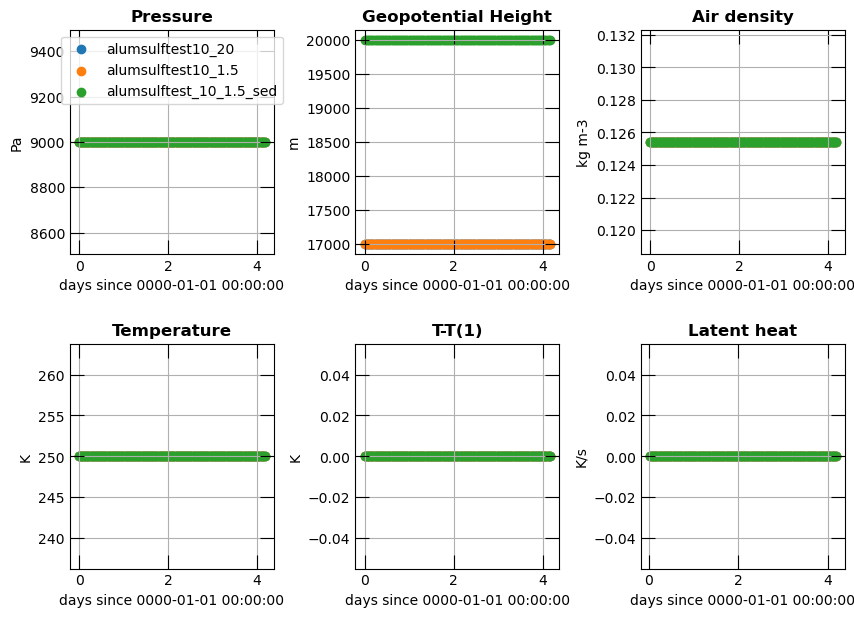

In [ ]:
fig, axs = plt.subplots(figsize=(10, 7), nrows=2, ncols=int(len(atm_vars)/2)) 
axs = axs.flatten()

fig.subplots_adjust(hspace=0.4, wspace=0.4)

for i, var in enumerate(atm_vars):
    for exp in exper_list:
        if var in ds[exp].keys(): 
            print(exp)
            print(ds[exp][var])
            axs[i].scatter(ds[exp].time, ds[exp][var], linestyle=line_exp[exp],  color=color_exp[exp], label=exp)
            axs[i].set_title(ds[exp][var].long_name, fontweight='bold') 
            axs[i].set_ylabel(ds[exp][var].units)

        ## Axis aspect 
        axs[i].grid()
        axs[i].tick_params( direction="in", length=10, top=True, right=True)
        axs[i].set_xlabel(ds[exp].time.units)
        axs[i].get_yaxis().get_major_formatter().set_useOffset(False)


axs[0].legend( loc='upper center', fancybox=True)

fig.patch.set_facecolor('white')
#fig.savefig(plot_dir +'atm.png', bbox_inches='tight')

## Gases

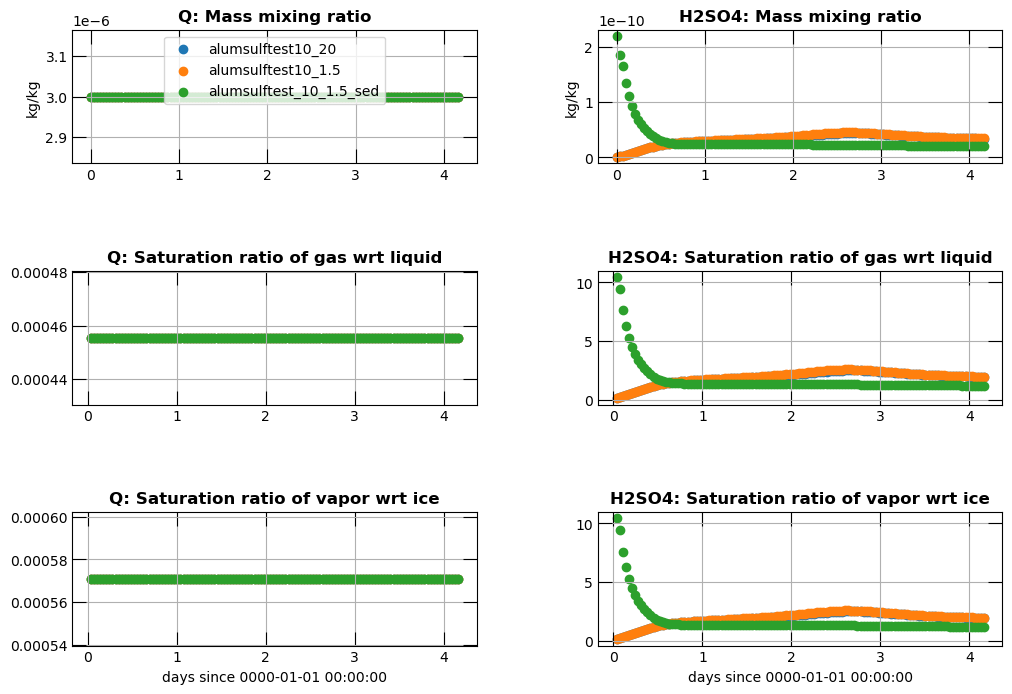

In [ ]:
fig, axs = plt.subplots(figsize=( 12, 8), nrows=len(gases_vars), ncols=len(gases)) 
axs = axs.flatten()

fig.subplots_adjust(hspace=0.8, wspace=0.3)

for g, gas in enumerate(gases):
    for v, var in enumerate(gases_vars):
        varname = gas + var
        i = len(gases) * v + g
        for exp in exper_list:
            if varname in ds[exp].keys(): 
                axs[i].scatter(ds[exp].time, ds[exp][varname], linestyle=line_exp[exp],  color=color_exp[exp], label=exp)
                axs[i].set_ylabel(ds[exp][varname].units)
                axs[i].set_title(gas + ': ' + ds[exp][varname].long_name, fontweight='bold')    
        
        ## Axis aspect      
        axs[i].grid()
        axs[i].tick_params( direction="in", length=10, top=True, right=True)
        axs[i].get_yaxis().get_major_formatter().set_useOffset(False)

[ axs[i].set_xlabel(ds[exp].time.units) for i in [-2,-1]]
axs[0].legend( loc='upper center', fancybox=True)

fig.patch.set_facecolor('white')
# fig.savefig(plot_dir +'gases.png', bbox_inches='tight')

## Groups

### Bins

PRSUL_r
ALSUL_r
PRSUL_rmass
ALSUL_rmass
PRSUL_vol
ALSUL_vol
PRSUL_arat
ALSUL_arat
PRSUL_rrat
ALSUL_rrat
PRSUL_rprat
ALSUL_rprat
PRSUL_rmass
ALSUL_rmass
PRSUL_df
ALSUL_df
PRSUL_nmon
ALSUL_nmon


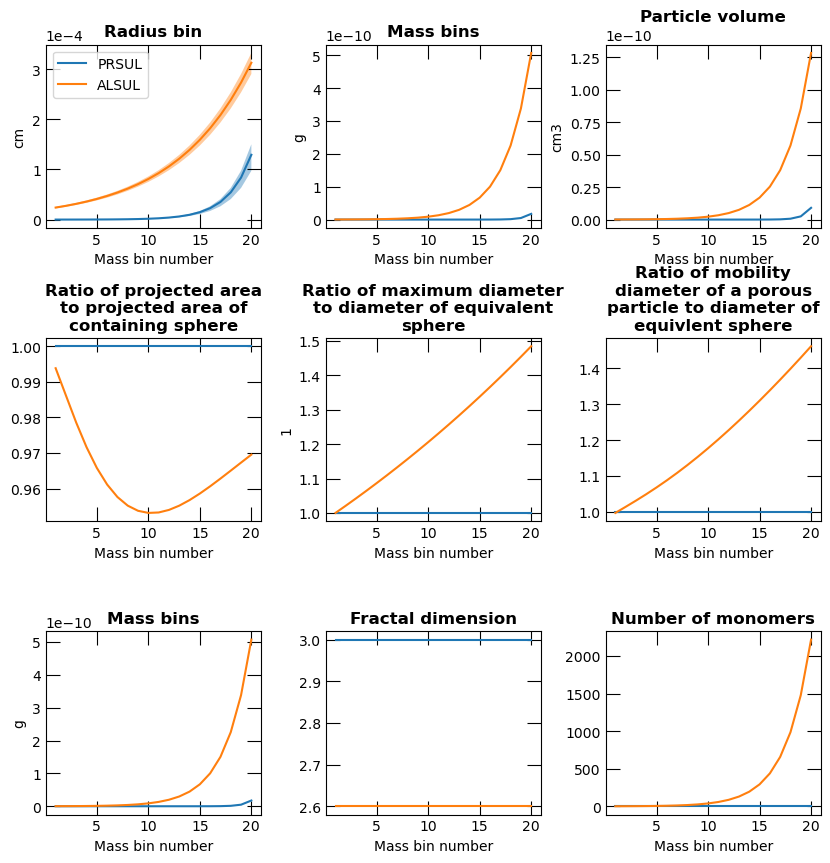

In [ ]:
fig, axs = plt.subplots(figsize=(10, 10), nrows=3, ncols=3)  
axs = axs.flatten()
fig.subplots_adjust(hspace=0.6, wspace=0.3)

                
for i, var in enumerate(['r', 'rmass', 'vol', 'arat', 'rrat', 'rprat', 'rmass', 'df', 'nmon']):
    for g, grp in enumerate(groups):
        varname = grp + '_' + var
        if varname in ds[exp].keys(): 
            print(varname)
            axs[i].plot(ds[exp].bin, ds[exp][varname], label=grp)    
            if var == 'r':
                axs[i].fill_between(ds[exp].bin, ds[exp][grp + '_rup'], ds[exp][grp + '_rlow'], alpha=0.4)
        
        ## Axis aspect
        axs[i].set_title( "\n".join(wrap(ds[exp][varname].long_name, 25)), fontweight='bold')
        axs[i].set_ylabel(ds[exp][varname].units)    
        axs[i].set_xlabel('Mass bin number')
        axs[i].grid()
        axs[i].tick_params( direction="in", length=10, top=True, right=True)
        # axs[i].set_ylim(bottom=0)
        axs[i].ticklabel_format(style='sci', scilimits=(-4,4), axis='y')


axs[0].legend( fancybox=True)

fig.patch.set_facecolor('white')
# fig.savefig(plot_dir +'bins.png', bbox_inches='tight')

### Group variables timeseries

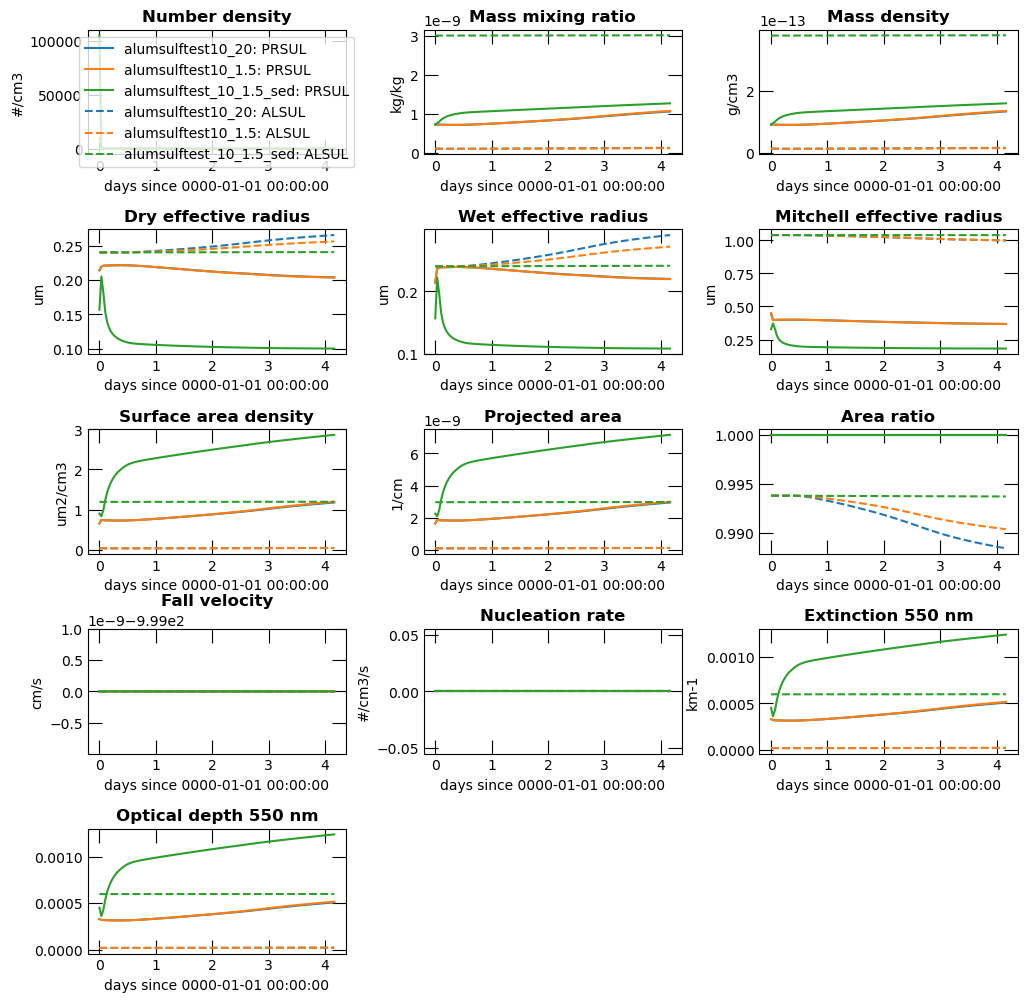

In [ ]:
fig, axs = plt.subplots(figsize=(12, 12), nrows=5, ncols=3) 
axs = axs.flatten()

fig.subplots_adjust(hspace=0.6, wspace=0.3)

for i, var in enumerate(groups_vars):
    for g, grp in enumerate(groups):
        varname = grp + var
        for e, exp in enumerate(exper_list):
            
            if varname in ds[exp].keys():
                axs[i].set_title(ds[exp][varname].long_name, fontweight='bold') 
                axs[i].plot(ds[exp].time, ds[exp][varname], linestyle=line_grp[grp], color=color_exp[exp], label=exp +': ' + grp)
                axs[i].set_ylabel(ds[exp][varname].units)
                # if var == 'RE':
                #     axs[i].plot(ds[exp].time, ds[exp][grp + 'REw'], linestyle='--',  color=color_grp[grp+exp])
                #     axs[i].set_title( 'Effective radius', fontweight='bold') 
                #     axs[i].legend(['dry', 'wet'])
        
        ## Axis aspect 
        axs[i].grid()
        axs[i].tick_params( direction="in", length=10, top=True, right=True)
        axs[i].set_xlabel(ds[exp].time.units)
        # axs[i].set_ylim(bottom=0)
#        axs[i].set_yscale('log')


[axs[j].axis('off') for j in range(i+1, len(axs))]

axs[0].legend( loc='upper center',  fancybox=True)
fig.patch.set_facecolor('white')
fig.savefig(plot_dir +'groups.png', bbox_inches='tight')

### Surface area density: H2SO4-coated vs. solid

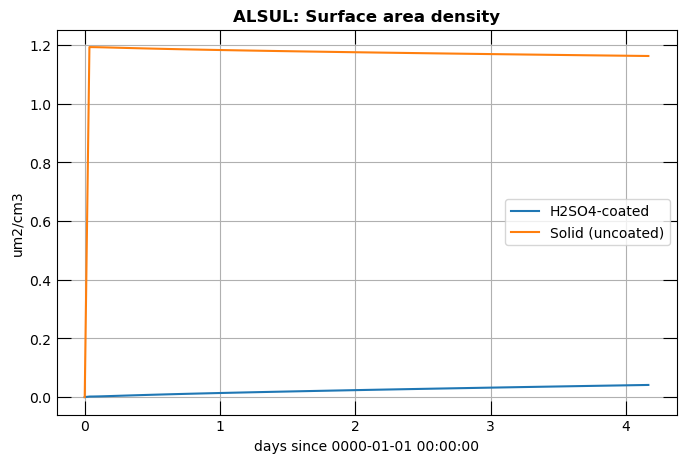

In [ ]:
def total_sad(ds_exp, group_name, bins, varname):
    """Sum a per-bin group variable (e.g. '<GROUP><bin>ADH2SO4') over all bins,
    returning a single time series of the bin-integrated surface area density."""
    bin_str = [str(int(n)) if n > 9 else "0" + str(int(n)) for n in bins]
    parts = [ds_exp[group_name + bn + varname] for bn in bin_str]
    da = xr.concat(parts, dim='bin').assign_coords({"bin": bins})
    return da.sum('bin')


sad_exp = 'alumsulftest_10_1.5_sed'
sad_grp = 'ALSUL'

ad_h2so4 = total_sad(ds[sad_exp], sad_grp, ds[sad_exp].bin, 'ADH2SO4')
ad_solid = total_sad(ds[sad_exp], sad_grp, ds[sad_exp].bin, 'ADSOLID')

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(ds[sad_exp].time, ad_h2so4, color='tab:blue', label='H2SO4-coated')
ax.plot(ds[sad_exp].time, ad_solid, color='tab:orange', label='Solid (uncoated)')

## Axis aspect
ax.set_title(sad_grp + ': Surface area density', fontweight='bold')
ax.set_xlabel(ds[sad_exp].time.units)
ax.set_ylabel('um2/cm3')
ax.grid()
ax.tick_params(direction="in", length=10, top=True, right=True)
ax.legend(fancybox=True)

fig.patch.set_facecolor('white')
fig.savefig(plot_dir + 'SAD_h2so4_vs_solid.png', bbox_inches='tight')


### Size distributions

In [ ]:
for grp in groups:
    for exp in exper_list:
        my_list = list(ds[exp].keys())
        wr_list = [item for item in my_list if 'WR' in item]
        nd_list = [item for item in my_list if 'ND' in item]
        wet_radius = ds[exp][wr_list]
        numdensity = ds[exp][nd_list]
        
    
        ds[exp][grp + 'dist'] = sizedist(grp, group_types[grp], ds[exp].bin, wet_radius, numdensity)


In [ ]:
time = ds['alumsulftest_sulf'].time[0:119:12]

fig, axs = plt.subplots(figsize=(10, 6), nrows=3, ncols=4) 
axs = axs.flatten()    
fig.subplots_adjust(top=0.9, hspace=0., wspace=0.)

exper_list = ['alumsulftest_sulf'] 

tt = [ 0, 1, 2,  4, 8, 12, 24, 48, 96] #  60,
ttt = ['0m', '30m', '1h','2h', '4h', '6h', '12h', '1d', '2d'] #  '1.5d',
# tt = [ 0, 1, 2,  4, 6, 8, 10] #  60,
# ttt = ['0m', '30m', '1h','2h', '3h', '4h', '5h'] #  '1.5d',


grp = groups[0]
fig.suptitle(grp, fontweight='bold', fontsize=15)
for i,tm in enumerate(time): 
    for e, exp in enumerate(exper_list): 
          
        vr = ds[exp][grp + 'dist'].sel(time=tm, method='nearest')
        axs[i].bar( ds[exp][grp + '_r'].values * 1e4, vr.values, 
            align='center', width=ds[exp][grp + '_dr'].values * 1e4, 
            edgecolor=color_exp[exp], color='none', label=exp)

    # # Axis aspect
    axs[i].set(yscale='log', yticks=[1e-4, 1e-2, 1e+0], ylim=[1e-6, 1e2])  
    axs[i].set(xscale='log',  xlim=[1e-1, 1.e+0],xticks=[2.e-1,4e-1])
    axs[i].set_title(str(round(tm.item(),1)) + ' days', y=0.82, fontweight='bold')
    axs[i].minorticks_on()
    axs[i].tick_params(which='major',direction="in", length=5, top=True, right=True)
    axs[i].tick_params(which='minor', direction="in", length=2.5, top=False, bottom=True, right=True, left=True)
    #axs[i].set(xscale='log', yscale='log', xticks=[1e-4, 1e-3, 1e-2, 1e-1, 1], xlim=[1e-4, 1e1], ylim=[1e-5, 1e4])
   
    if i > 7:
        axs[i].set_xticklabels([])
        axs[i].set_xlabel('microns')

    if i%4:
        axs[i].set_yticklabels([])
    else:
        axs[i].set_ylabel('number density')

axs[3].legend(loc='center', bbox_to_anchor=(1.6, 0.5))


fig.patch.set_facecolor('white')
fig.savefig(plot_dir +'NDdist' + grp + '.png', bbox_inches='tight')

KeyError: 'alumsulftest_sulf'

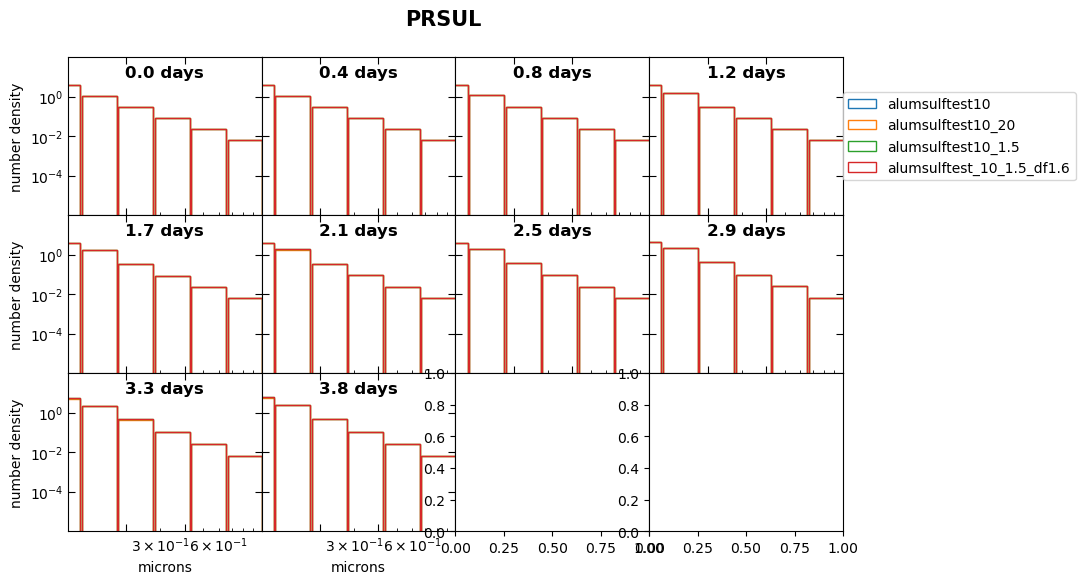

In [ ]:
time = ds['alumsulftest10_1.5'].time[0:119:12]

fig, axs = plt.subplots(figsize=(10, 6), nrows=3, ncols=4) 
axs = axs.flatten()    
fig.subplots_adjust(top=0.9, hspace=0., wspace=0.)

#exper_list = ['alumsulftest10','alumsulftest10_20','alumsulftest12','alumsulftest12_20'] 
#exper_list = ['alumsulftest10_20','alumsulftest10_1.5','alumsulftest12_20','alumsulftest12_1.5'] 
exper_list = ['alumsulftest10','alumsulftest10_20','alumsulftest10_1.5','alumsulftest_10_1.5_df1.6'] 



tt = [ 0, 1, 2,  4, 8, 12, 24, 48, 96] #  60,
ttt = ['0m', '30m', '1h','2h', '4h', '6h', '12h', '1d', '2d'] #  '1.5d',
# tt = [ 0, 1, 2,  4, 6, 8, 10] #  60,
# ttt = ['0m', '30m', '1h','2h', '3h', '4h', '5h'] #  '1.5d',


grp = groups[0]
fig.suptitle(grp, fontweight='bold', fontsize=15)
for i,tm in enumerate(time): 
    for e, exp in enumerate(exper_list): 
          
        vr = ds[exp][grp + 'dist'].sel(time=tm, method='nearest')
        axs[i].bar( ds[exp][grp + '_r'].values * 1e4, vr.values, 
            align='center', width=ds[exp][grp + '_dr'].values * 1e4, 
            edgecolor=color_exp[exp], color='none', label=exp)

    # # Axis aspect
    axs[i].set(yscale='log', yticks=[1e-4, 1e-2, 1e+0], ylim=[1e-6, 1e2])  
    axs[i].set(xscale='log',  xlim=[1e-1, 1.e+0],xticks=[2.e-1,4e-1])
    axs[i].set_title(str(round(tm.item(),1)) + ' days', y=0.82, fontweight='bold')
    axs[i].minorticks_on()
    axs[i].tick_params(which='major',direction="in", length=5, top=True, right=True)
    axs[i].tick_params(which='minor', direction="in", length=2.5, top=False, bottom=True, right=True, left=True)
   
    if i > 7:
        axs[i].set_xticklabels([])
        axs[i].set_xlabel('microns')

    if i%4:
        axs[i].set_yticklabels([])
    else:
        axs[i].set_ylabel('number density')

axs[3].legend(loc='center', bbox_to_anchor=(1.6, 0.5))


fig.patch.set_facecolor('white')
fig.savefig(plot_dir +'NDdist' + grp + '.png', bbox_inches='tight')

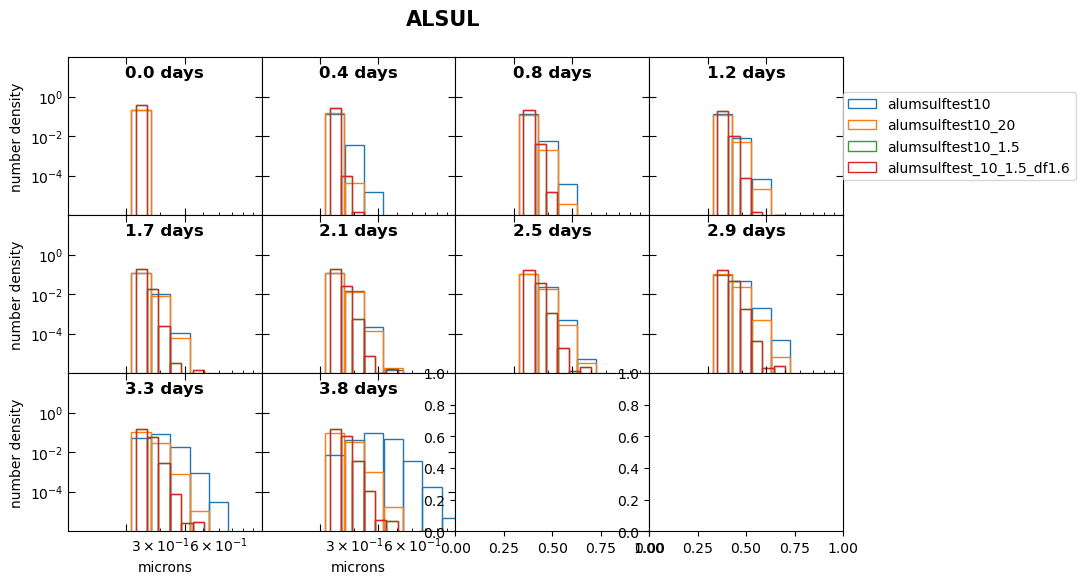

In [ ]:
time = ds['alumsulftest10_1.5'].time[0:119:12]

fig, axs = plt.subplots(figsize=(10, 6), nrows=3, ncols=4) 
axs = axs.flatten()    
fig.subplots_adjust(top=0.9, hspace=0., wspace=0.)

#exper_list = ['alumsulftest10','alumsulftest10_20','alumsulftest12','alumsulftest12_20'] 
#exper_list = ['alumsulftest10_20','alumsulftest12_20'] 
#exper_list = ['alumsulftest10_20','alumsulftest10_1.5','alumsulftest12_20','alumsulftest12_1.5'] 
#exper_list = ['alumsulftest12_20','alumsulftest12_1.5'] 
exper_list = ['alumsulftest10','alumsulftest10_20','alumsulftest10_1.5','alumsulftest_10_1.5_df1.6']  
#exper_list = ['alumsulftest10_1.5','alumsulftest_10_1.5_df1.6','alumsulftest12_1.5','alumsulftest_12_1.5_df1.6']  



tt = [ 0, 1, 2,  4, 8, 12, 24, 48, 96] #  60,
ttt = ['0m', '30m', '1h','2h', '4h', '6h', '12h', '1d', '2d'] #  '1.5d',
# tt = [ 0, 1, 2,  4, 6, 8, 10] #  60,
# ttt = ['0m', '30m', '1h','2h', '3h', '4h', '5h'] #  '1.5d',


grp = groups[1]
fig.suptitle(grp, fontweight='bold', fontsize=15)
for i,tm in enumerate(time): 
    for e, exp in enumerate(exper_list): 
          
        vr = ds[exp][grp + 'dist'].sel(time=tm, method='nearest')
        axs[i].bar( ds[exp][grp + '_r'].values * 1e4, vr.values, 
            align='center', width=ds[exp][grp + '_dr'].values * 1e4, 
            edgecolor=color_exp[exp], color='none', label=exp)

    # # Axis aspect
    axs[i].set(yscale='log', yticks=[1e-4, 1e-2, 1e+0], ylim=[1e-6, 1e2])  
    axs[i].set(xscale='log',  xlim=[1e-1, 1.e+0],xticks=[2.e-1,4e-1])
    axs[i].set_title(str(round(tm.item(),1)) + ' days', y=0.82, fontweight='bold')
    axs[i].minorticks_on()
    axs[i].tick_params(which='major',direction="in", length=5, top=True, right=True)
    axs[i].tick_params(which='minor', direction="in", length=2.5, top=False, bottom=True, right=True, left=True)
   
    if i > 7:
        axs[i].set_xticklabels([])
        axs[i].set_xlabel('microns')

    if i%4:
        axs[i].set_yticklabels([])
    else:
        axs[i].set_ylabel('number density')

axs[3].legend(loc='center', bbox_to_anchor=(1.6, 0.5))


fig.patch.set_facecolor('white')
fig.savefig(plot_dir +'NDdist' + grp + '.png', bbox_inches='tight')

In [ ]:
fig, axs = plt.subplots(figsize=(10, 6), nrows=3, ncols=3) 
axs = axs.flatten()    
fig.subplots_adjust(top=0.9, hspace=0., wspace=0.)


tt = [ 0, 1, 2,  4, 6, 8, 10] #  60,
ttt = ['0m', '30m', '1h','2h', '3h', '4h', '5h'] #  '1.5d',

grp = groups[1]    
for i, t in enumerate(tt):
    for exp in exper_list:
           
           
        vr = ds[exp][grp + 'dist'].sel(time = ds[exp].time[t])
        axs[i].bar( ds[exp]['bin'], vr.values, 
            align='center', width=1, edgecolor=sns.color_palette()[1], color='none', label=grp)

        axs[i].set(xticks=ds[exp]['bin'], yticks=np.arange(0.01, 1., 0.2), xlim=[0., 10],
                   ylim=[0., 1.04])


     # Axis aspect
    axs[i].set_title( 't= ' + ttt[i], y=0.82, fontweight='bold')
    axs[i].minorticks_on()
    axs[i].tick_params(which='major',direction="in", length=5, top=True, right=True)
    axs[i].tick_params(which='minor', direction="in", length=2.5, top=False, bottom=False, right=True, left=True)
    
    if i < 6:
        axs[i].set_xticklabels([])

    if i%3:
        axs[i].set_yticklabels([])

axs[0].legend()


plt.suptitle('Number density fraction per agglomerate', fontweight='bold', fontsize=16)
axs[3].set_ylabel("Fraction", fontweight='bold', fontsize=14 )
axs[-2].set_xlabel(r'Bin', fontsize=14 )


fig.patch.set_facecolor('white')
fig.savefig(plot_dir +'NDdist.png', bbox_inches='tight')

## Elements

In [ ]:
exper_list = ['alumsulftest10_1.5'] 

def massfrct(group_name, element_name, bins, group_mmr, element_mmr): 
    bin_str = [ str(int(n)) if n > 9 else "0"+str(int(n)) for n in bins]
    
    elm_tmp = []
    grp_tmp = []
    for bn in bin_str:
        elm_tmp.append(element_mmr[element_name + bn + 'MR'])
        grp_tmp.append(group_mmr[group_name + bn + 'MR'])
        
    elm_xr = xr.concat(elm_tmp, dim='bin').assign_coords({"bin": bins})   
    grp_xr = xr.concat(elm_tmp, dim='bin').assign_coords({"bin": bins})   
    dist = elm_xr/grp_xr
    dist = dist.assign_attrs(long_name="Mass fraction", units='', description='Fraction')


    return dist

In [ ]:
grp = groups[0]

for exp in exper_list:
    for elm in elements:    
        print(elm)
        my_list = list(ds[exp].keys())
        mmr_list = [item for item in my_list if 'MR' in item]
        elm_list = [item for item in mmr_list if elm in item]
        print(elm_list)
        print(mmr_list)
        grp_list = [item for item in mmr_list if grp in item]
        elm_mmr = ds[exp][elm_list]
        grp_mmr = ds[exp][grp_list]
        
    
        ds[exp][elm + 'massfrac'] = massfrct(grp, elm, ds[exp]['bin'], grp_mmr, elm_mmr)


PRSULF
['PRSULF01MR', 'PRSULF02MR', 'PRSULF03MR', 'PRSULF04MR', 'PRSULF05MR', 'PRSULF06MR', 'PRSULF07MR', 'PRSULF08MR', 'PRSULF09MR', 'PRSULF10MR', 'PRSULF11MR', 'PRSULF12MR', 'PRSULF13MR', 'PRSULF14MR', 'PRSULF15MR', 'PRSULF16MR', 'PRSULF17MR', 'PRSULF18MR', 'PRSULF19MR', 'PRSULF20MR']
['PRSULF01MR', 'PRSULF02MR', 'PRSULF03MR', 'PRSULF04MR', 'PRSULF05MR', 'PRSULF06MR', 'PRSULF07MR', 'PRSULF08MR', 'PRSULF09MR', 'PRSULF10MR', 'PRSULF11MR', 'PRSULF12MR', 'PRSULF13MR', 'PRSULF14MR', 'PRSULF15MR', 'PRSULF16MR', 'PRSULF17MR', 'PRSULF18MR', 'PRSULF19MR', 'PRSULF20MR', 'ALSULF01MR', 'ALSULF02MR', 'ALSULF03MR', 'ALSULF04MR', 'ALSULF05MR', 'ALSULF06MR', 'ALSULF07MR', 'ALSULF08MR', 'ALSULF09MR', 'ALSULF10MR', 'ALSULF11MR', 'ALSULF12MR', 'ALSULF13MR', 'ALSULF14MR', 'ALSULF15MR', 'ALSULF16MR', 'ALSULF17MR', 'ALSULF18MR', 'ALSULF19MR', 'ALSULF20MR', 'ALUM01MR', 'ALUM02MR', 'ALUM03MR', 'ALUM04MR', 'ALUM05MR', 'ALUM06MR', 'ALUM07MR', 'ALUM08MR', 'ALUM09MR', 'ALUM10MR', 'ALUM11MR', 'ALUM12MR', 'ALUM13

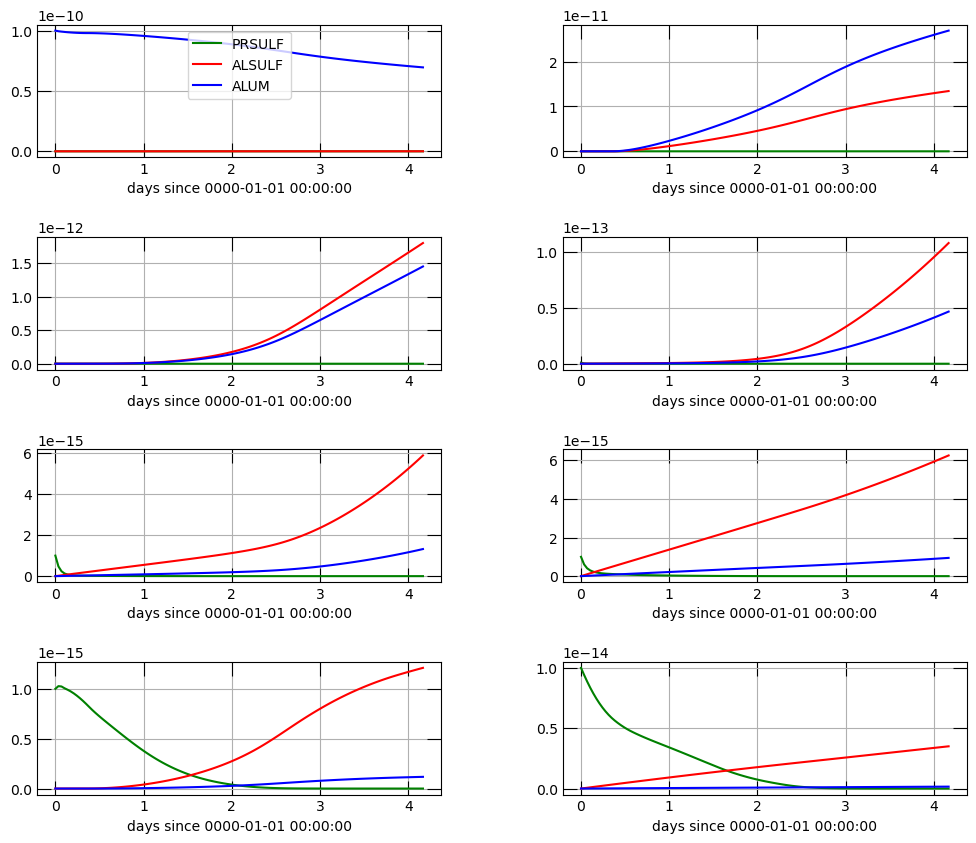

In [ ]:
fig, axs = plt.subplots(figsize=(12, 10), nrows=4, ncols=2) 
axs = axs.flatten()

color_elm = ['g','r','b']

fig.subplots_adjust(hspace=0.6, wspace=0.3)
data = np.random.randn(20)
for exp in exper_list:
    for e, elm in enumerate(elements):    
          my_list = list(ds[exp].keys())
          mmr_list = [item for item in my_list if 'MR' in item]
          elm_list = [item for item in mmr_list if elm in item]
          data = ds[exp][elm_list].to_dataarray()
          for i in range(0, 8):

              if (elm=='PRSULF'):
                  axs[i].plot(ds[exp].time, data[i,:], linestyle=line_exp[exp], color=color_elm[e], label=elm)
              if (elm=='ALSULF'):
                  axs[i].plot(ds[exp].time, data[i,:], linestyle=line_exp[exp], color=color_elm[e], label=elm)
              if (elm=='ALUM'):
                  axs[i].plot(ds[exp].time, data[i,:], linestyle=line_exp[exp], color=color_elm[e], label=elm)
        
        ## Axis aspect 
              axs[i-2].grid()
              axs[i-2].tick_params( direction="in", length=10, top=True, right=True)
              axs[i-2].set_xlabel(ds[exp].time.units)
              #axs[i-2].set_yscale('log')


axs[0].legend( loc='upper center',  fancybox=True)
fig.patch.set_facecolor('white')
fig.savefig(plot_dir +'groups.png', bbox_inches='tight')


['PRSULF', 'ALSULF', 'ALUM']
PRSULF
['PRSULF01MR', 'PRSULF02MR', 'PRSULF03MR', 'PRSULF04MR', 'PRSULF05MR', 'PRSULF06MR', 'PRSULF07MR', 'PRSULF08MR', 'PRSULF09MR', 'PRSULF10MR', 'PRSULF11MR', 'PRSULF12MR', 'PRSULF13MR', 'PRSULF14MR', 'PRSULF15MR', 'PRSULF16MR', 'PRSULF17MR', 'PRSULF18MR', 'PRSULF19MR', 'PRSULF20MR']
PRSULF
PRSULF
PRSULF
PRSULF
PRSULF
PRSULF
PRSULF
PRSULF
ALSULF
['ALSULF01MR', 'ALSULF02MR', 'ALSULF03MR', 'ALSULF04MR', 'ALSULF05MR', 'ALSULF06MR', 'ALSULF07MR', 'ALSULF08MR', 'ALSULF09MR', 'ALSULF10MR', 'ALSULF11MR', 'ALSULF12MR', 'ALSULF13MR', 'ALSULF14MR', 'ALSULF15MR', 'ALSULF16MR', 'ALSULF17MR', 'ALSULF18MR', 'ALSULF19MR', 'ALSULF20MR']
ALSULF
ALSULF
ALSULF
ALSULF
ALSULF
ALSULF
ALSULF
ALSULF
ALUM
['ALUM01MR', 'ALUM02MR', 'ALUM03MR', 'ALUM04MR', 'ALUM05MR', 'ALUM06MR', 'ALUM07MR', 'ALUM08MR', 'ALUM09MR', 'ALUM10MR', 'ALUM11MR', 'ALUM12MR', 'ALUM13MR', 'ALUM14MR', 'ALUM15MR', 'ALUM16MR', 'ALUM17MR', 'ALUM18MR', 'ALUM19MR', 'ALUM20MR']
ALUM
ALUM
ALUM
ALUM
ALUM
ALUM
ALUM
AL

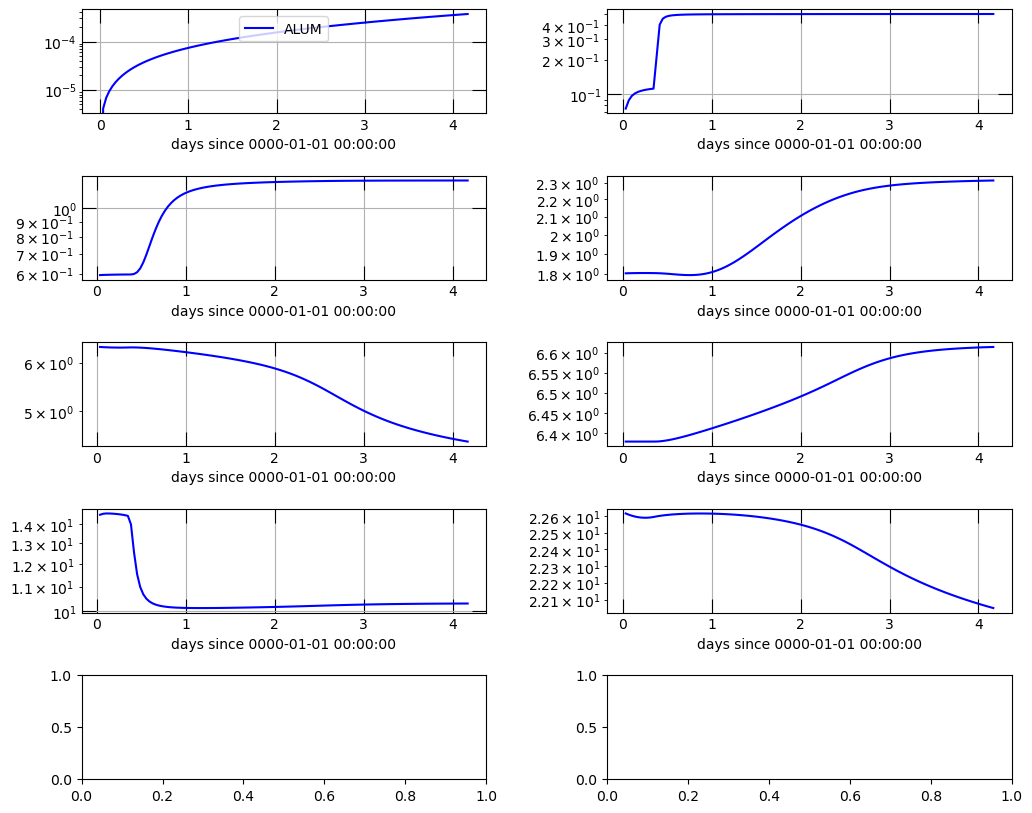

In [ ]:
fig, axs = plt.subplots(figsize=(12, 10), nrows=5, ncols=2) 
axs = axs.flatten()

color_elm = ['g','r','b']
print(elements)
fig.subplots_adjust(hspace=0.6, wspace=0.3)
data = np.random.randn(20)
for exp in exper_list:
    for e, elm in enumerate(elements):    
          print(elm)
          my_list = list(ds[exp].keys())
          mmr_list = [item for item in my_list if 'MR' in item]
          elm_list = [item for item in mmr_list if elm in item]
          data = ds[exp][elm_list].to_dataarray()
          if (elm=='ALSULF'):
              alsulf = data
          if (elm=='ALUM'):
              alum = data
          print(elm_list)
          for i in range(2, 10):
              print(elm)
              # if (elm=='ALSULF'):
              #     axs[i-2].plot(ds[exp].time, data[i-2,:], linestyle=line_exp[exp], color=color_elm[e], label=elm)
              # if (elm=='ALUM'):
              #     axs[i-2].plot(ds[exp].time, data[i-2,:], linestyle=line_exp[exp], color=color_elm[e], label=elm)
              if (elm=='ALUM'):
                  axs[i-2].plot(ds[exp].time, (alsulf[i-2,:]/alum[i-2,:]), linestyle=line_exp[exp], color=color_elm[e], label=elm)
        
        ## Axis aspect 
              axs[i-2].grid()
              axs[i-2].tick_params( direction="in", length=10, top=True, right=True)
              axs[i-2].set_xlabel(ds[exp].time.units)
              axs[i-2].set_yscale('log')


axs[0].legend( loc='upper center',  fancybox=True)
fig.patch.set_facecolor('white')
fig.savefig(plot_dir +'groups.png', bbox_inches='tight')

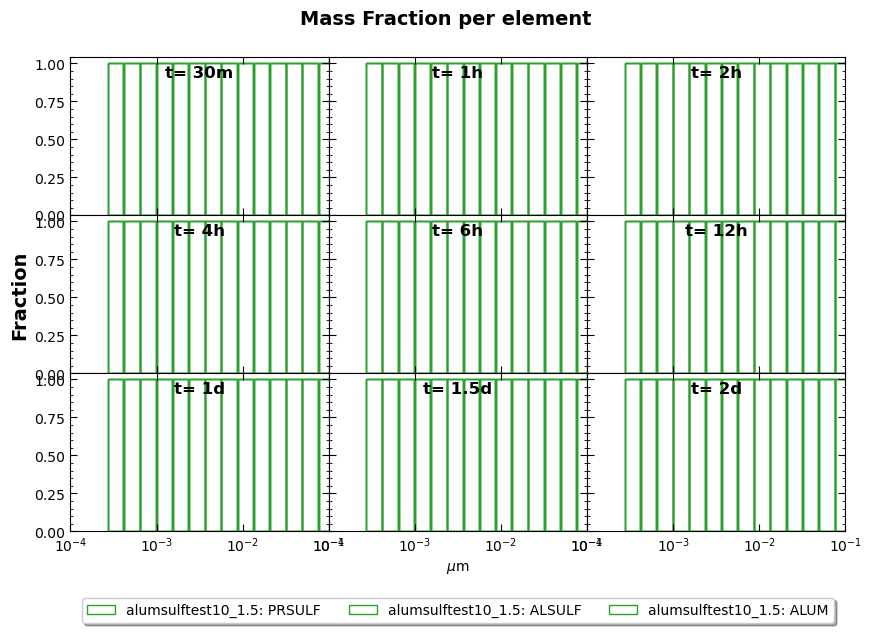

In [ ]:
fig, axs = plt.subplots(figsize=(10, 6), nrows=3, ncols=3) 
axs = axs.flatten()    
fig.subplots_adjust(top=0.9, hspace=0., wspace=0.)


tt = [ 1, 2,  4, 8, 12, 24, 48, 60, 96]
ttt = ['30m', '1h','2h', '4h', '6h', '12h', '1d', '1.5d', '2d']

for i, t in enumerate(tt):
    for exp in exper_list:
        for elm in elements:
        
            vr = ds[exp][elm + 'massfrac'].sel(time = ds[exp].time[t])

            if group_types[grp] == 'standard':
                    axs[i].bar( ds[exp][grp + '_r'].values * 1e4, vr.values, 
                       align='center', width=ds[exp][grp + '_dr'].values * 1e4, 
                       edgecolor=color_grp[grp+exp], color='none', label=exp + ': ' + elm)
    
                        
                    axs[i].set(xscale='log', xticks=[1e-4, 1e-3, 1e-2, 1e-1, 1], xlim=[1e-4, 1e-1], ylim=[0, 1.04])
                    
               
            elif group_types[grp] == 'fractal':
                    axs[i].bar( ds[exp]['bin'], vr.values, 
                        align='center', width=1, edgecolor=color_exp[exp], color='none', label=exp + ': ' + elm)
    
                    axs[i].set( xticks=ds[exp]['bin'], yticks=np.arange(0.0, 1., 0.2), xlim=[0., len(ds[exp]['bin'])+1], ylim=[0, 1.04])
                   
           
     # Axis aspect
    axs[i].set_title( 't= ' + ttt[i], y=0.82, fontweight='bold')
    axs[i].minorticks_on()
    axs[i].tick_params(which='major',direction="in", length=5, top=True, right=True)
    axs[i].tick_params(which='minor', direction="in", length=2.5, top=False, bottom=False, right=True, left=True)
    
    if i < 6:
        axs[i].set_xticklabels([])

    if i%3:
        axs[i].set_yticklabels([])
        

axs[-2].legend(loc='center', bbox_to_anchor=(0.5, -0.5), fancybox=True, shadow=True, ncols=3)
axs[3].set_ylabel("Fraction", fontweight='bold', fontsize=14 )
fig.suptitle("Mass Fraction per element", fontweight='bold', fontsize=14 )

if group_types[grp] == 'standard':
    axs[-2].set_xlabel(r'$\mu$m')
elif group_types[grp] == 'fractal':
    axs[-2].set_xlabel(r'Bin')


fig.patch.set_facecolor('white')
fig.savefig(plot_dir +'Massdist.png', bbox_inches='tight')